# Week 4 · Functions you can trust · Midterm

Every part you have built is a function. This week you make functions that people can rely on: a clear promise, one returned answer, and tests that prove it. Session 3 is your individual midterm.

| | |
|---|---|
| **This week's question** | How can you show that a function keeps its promise? |
| **Python you will learn** | `def`, parameters and arguments, `return` vs `print`, `None`, docstrings, functions that call functions, `assert`, test functions |
| **Principle 4** | **One function, one job.** Return values instead of printing them. Test normal, boundary and odd cases. |
| **Part you build** | `open_portions` and your own tests |
| **Session 3** | the individual midterm, in `Midterm.ipynb` |

*Campus Food Rescue is fictional. All organisations, people and numbers are invented.*

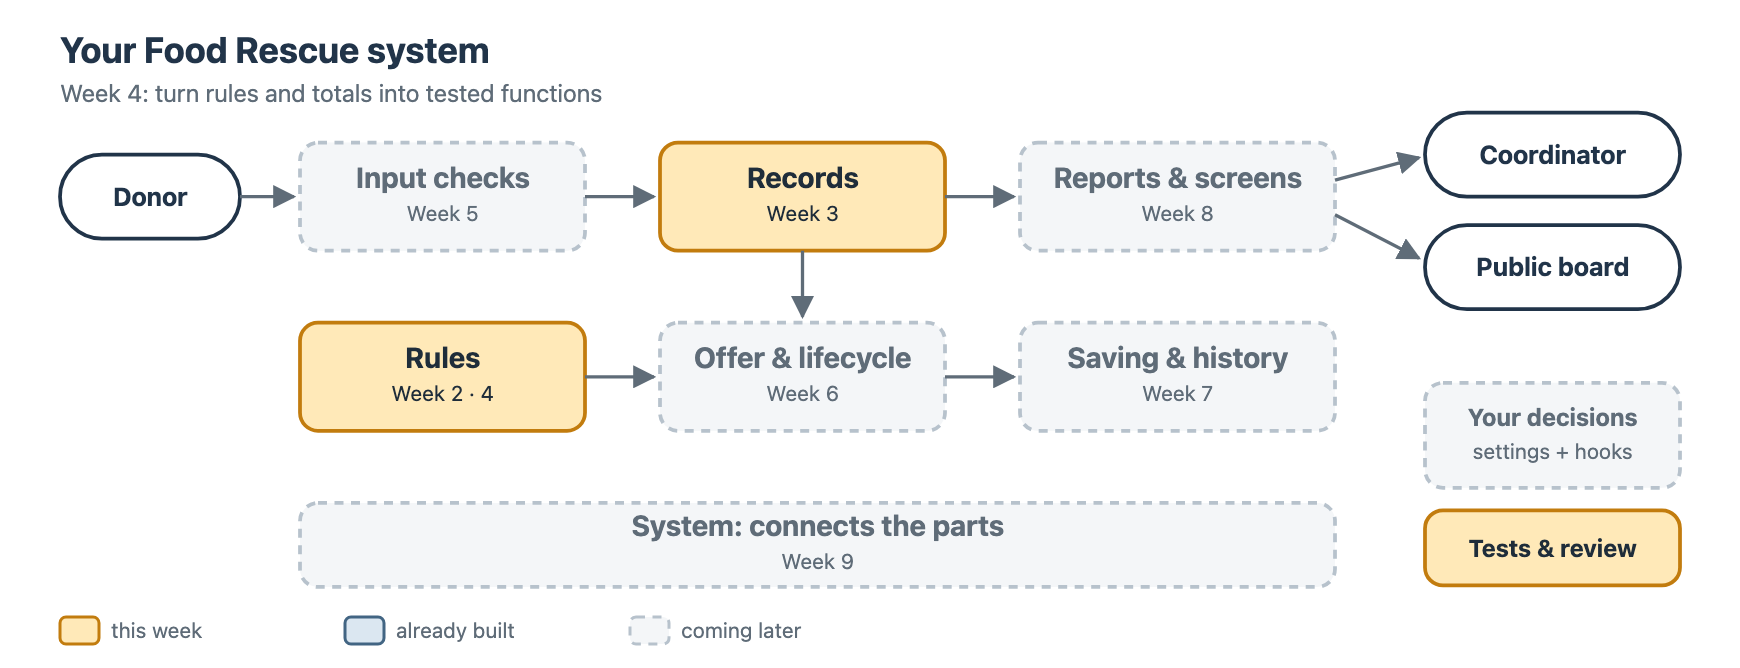

## Before you start

1. **File → Save a copy in Drive**, then work in your copy.
2. Run the setup cell. Run it again after a runtime restart.
3. ⭐ = core for everyone, ⭐⭐ = optional stretch.
4. This notebook covers Sessions 1 and 2. Session 3 is the midterm: read the short section at the end.

In [ ]:
# @title ▶ Run this cell first (setup) — it prepares the Food Rescue system
# It unpacks the course system that is stored inside this notebook.
# No internet, no installation. Run it again after Colab restarts.
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.1"
_KIT_SHA = "01f7d8b96143a6503649613b251e4fa2c46545a5d2a3e781617d8ad990f5189c"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("This notebook's course files are damaged. Download a fresh copy.")
    marker = os.path.join("food_rescue_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("food_rescue_kit/my_settings.py", "food_rescue_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("food_rescue_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "rescue" or m.startswith("rescue.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import rescue as fr
print("✅ Food Rescue system ready (version " + fr.KIT_VERSION + "). You can continue.")


## Session 1 · Learn and practise (90 min)

### The idea: modules and contracts

A phone charger makes a promise. Wall power goes in, safe power for your phone comes out, and it never damages the phone. You do not need to know what is inside. You trust it because it keeps the same promise every time, and because someone tested it.

A function is the same. Its **contract** says three things:

- **Inputs:** what you must give it. `find_offer` needs a list of records and an ID.
- **Output:** what it returns. `find_offer` returns the record, or `None` when there is no such ID.
- **What it never does.** `find_offer` never changes the list you give it, and never prints.

A **module** is a file of functions with contracts. The kit's `fr.records` module is one: the system's own `total_portions` and `find_offer` live there. When every part keeps its contract, you can build a system from parts, and replace one part (with your own function, or one an AI wrote) without breaking the others. A **test** is how you *show* that a part keeps its contract.

### 1 · Parameters and arguments

**Parameters** are the names in the `def` line: the function's inputs. **Arguments** are the values you give when you call it. Python matches them by position: the first argument goes to the first parameter. You can also give them by name.

🤔 **Predict** the last line before you run the cell.

In [ ]:
def price_after_discount(price_riel, discount_percent):
    return price_riel - price_riel * discount_percent // 100

print(price_after_discount(10000, 10))
print(price_after_discount(discount_percent=25, price_riel=4000))   # by name: order does not matter
print(price_after_discount(10, 10000))                              # 🤔 arguments swapped

**Prediction:** …  **Result:** …

A price of −990 riel is nonsense, but Python does not know that. Only a person, or a test, notices. Clear parameter names (with units) make swapped arguments easier to spot.

### 2 · `return` or `print`?

Both functions below add up the same prices. Only one gives the answer back.

In [ ]:
def total_printed(prices_riel):
    total = 0
    for price_riel in prices_riel:
        total += price_riel
    print(total)

def total_returned(prices_riel):
    total = 0
    for price_riel in prices_riel:
        total += price_riel
    return total

printed_result = total_printed([4000, 1500])
returned_result = total_returned([4000, 1500])
print("printed_result is", printed_result)
print("returned_result is", returned_result)

- `print` **shows** a value to a person. Then it is gone.
- `return` **gives** the value back to the code that called the function. That code can add it, compare it, test it or put it in a report.

The system never reads the screen. A function that only prints is useless to the rest of the system, and impossible to test.

### 3 · `None` means "no answer"

A function that ends without `return` gives back `None`. That is what happened to `printed_result`. Sometimes `None` is **on purpose**: `find_offer` returns `None` to say "not found". Check for it with `is None`.

In [ ]:
prices_by_item = {"notebook": 4000, "pen": 1500}

def find_price(item_name):
    return prices_by_item.get(item_name)

price = find_price("ruler")
if price is None:
    print("Not sold here")
else:
    print(price, "riel")

`None` on purpose is part of the contract, so write it down. `None` by accident (a forgotten `return`) is a bug.

### 4 · Docstrings: write the promise down

A **docstring** is text in triple quotes on the first line inside a function. It states the contract. `help(...)` shows it. The kit's functions have docstrings too.

In [ ]:
def average_mark(marks):
    """Return the average of a list of marks.

    Returns 0 for an empty list. Does not change the list.
    """
    if len(marks) == 0:
        return 0
    total = 0
    for mark in marks:
        total += mark
    return total / len(marks)

help(average_mark)
help(fr.records.find_offer)

### 5 · Functions that call functions

Build big functions from small ones. Each small function does **one job** and can be tested alone.

In [ ]:
URGENT_HOURS = 3

def is_urgent(hours_left):
    return hours_left <= URGENT_HOURS

def urgent_portions(records):
    """Return the total portions of urgent records. Does not change records."""
    total = 0
    for record in records:
        if is_urgent(record["hours_left"]):
            total += record["portions"]
    return total

print(urgent_portions(fr.sample_records()))

`is_urgent` decides; `urgent_portions` adds up. If the coordinator changes what "urgent" means, you change one place.

### 6 · `assert`: a check that stops loudly

`assert` checks that something is `True`. If it is, nothing happens. If it is not, Python stops with an `AssertionError`. A broken promise should never pass quietly.

In [ ]:
assert price_after_discount(10000, 10) == 9000
assert average_mark([]) == 0
print("Both asserts passed")
# assert average_mark([50, 70]) == 50    # remove the # to see a failing assert, then put it back

### 7 · Test functions: normal, boundary and empty

A **test function** has a name that starts with `test_`, and it uses `assert` to check one case. Good tests cover three kinds of case:

| Kind | The question | For `average_mark` |
|---|---|---|
| **normal** | Does it work for a usual input? | `[60, 80]` → 70 |
| **boundary** | Does it work at the edge? | `[0, 100]` → 50; `[100]` → 100 |
| **empty or odd** | Missing, empty or unusual input? | `[]` → 0 |

The cell also defines `run_tests`, a tiny test runner. You do not need to write one; just read it. It calls each test and prints ✅ when no `assert` failed, or ❌ with the reason. (`try`/`except` lets the notebook continue after a failure; you will learn it in Week 5.)

In [ ]:
def run_tests(tests):
    """Run each test function. Print ✅ or ❌ for each one; never stop the notebook."""
    passed = 0
    for test in tests:
        try:
            test()
            print("✅", test.__name__)          # every function knows its own name
            passed += 1
        except AssertionError as problem:
            print("❌", test.__name__, "→", problem)
        except Exception as problem:
            print("❌", test.__name__, "→ error:", type(problem).__name__, problem)
    print(passed, "of", len(tests), "tests passed")

def test_average_normal():
    assert average_mark([60, 80]) == 70

def test_average_boundary():
    assert average_mark([0, 100]) == 50
    assert average_mark([100]) == 100

def test_average_empty():
    assert average_mark([]) == 0

run_tests([test_average_normal, test_average_boundary, test_average_empty])

Notice `run_tests([test_average_normal, ...])`: you give the **functions** without `( )`. The runner calls them.

### ⭐ P1 · Return, don't print

The coordinator's screen should say *"Send a volunteer now"* when at least one offer is urgent. This function counts urgent offers, but the screen cannot use its answer. Fix it, then remove the `#` from the last two lines.

In [ ]:
def count_urgent(hours_left_list):
    count = 0
    for hours_left in hours_left_list:
        if hours_left <= URGENT_HOURS:
            count += 1
    print(count)

result = count_urgent([2, 5, 3, 20])
print("result is", result)
# if result > 0:                       # remove the # on these two lines after your fix
#     print("Send a volunteer now")

<details><summary>Show a possible answer</summary>

Replace `print(count)` with `return count`. Before the fix, `result` is `None`, and `None > 0` stops with a `TypeError`. After the fix: `result is 2` and `Send a volunteer now`. If a person also wants to see the number, print it **outside** the function: `print(count_urgent(...))`.

</details>

### ⭐ P2 · Predict: arguments and `None`

Write your prediction for each printed line, then run.

In [ ]:
def portions_each(portions, volunteers):
    return portions // volunteers

def greet(name):
    print("Hello,", name)

print(portions_each(30, 4))
print(portions_each(4, 30))
answer = greet("Dara")
print(answer)

**Predictions:** …  **Results:** …

<details><summary>Show a possible answer</summary>

`7`, `0`, `Hello, Dara`, `None`. Swapping the arguments gives 4 // 30 = 0: no error, just a wrong answer. `greet` prints but returns nothing, so `answer` is `None`.

</details>

### ⭐ P3 · Round up

A class trip: each minibus has `SEATS_PER_MINIBUS` seats. Nobody can travel in half a minibus, so if even one student is left over, you need one more. Write `minibuses_needed(students)`. Expected: 24 → 2, 25 → 3, 12 → 1, 0 → 0.

Hint (Week 1): `//` gives the number of **full** minibuses; `%` tells you whether anyone is **left over**.

In [ ]:
SEATS_PER_MINIBUS = 12

def minibuses_needed(students):
    """Return how many minibuses carry this many students. 0 students need 0 minibuses."""
    # TODO: full minibuses with //, then one more if % shows anyone left over
    return None

print(minibuses_needed(24), minibuses_needed(25), minibuses_needed(12), minibuses_needed(0))

<details><summary>Show the expected result and two traps</summary>

Expected: `2 3 1 0`. If you get something else, test 24 (exactly two full minibuses) and 0 first.

Two tempting shortcuts are wrong. `students / SEATS_PER_MINIBUS` gives `2.083…`, which is not a number of minibuses. `students // SEATS_PER_MINIBUS + 1` gives 3 for exactly 24 students: one bus too many **at the boundary**, and 1 bus for 0 students.

</details>

### ⭐ P4 · Tests that follow the constant

Write three tests for `minibuses_needed`. Write the amounts **with the constant**: `minibuses_needed(SEATS_PER_MINIBUS + 1)`, not `minibuses_needed(13)`. Then your tests still say the right thing when the decision changes.

In [ ]:
def test_minibuses_normal():
    # TODO: two full minibuses plus one more student need 3 minibuses
    assert False, "write this test"

def test_minibuses_boundary():
    # TODO: exactly one full minibus needs 1; one more student needs 2
    assert False, "write this test"

def test_minibuses_empty():
    # TODO: 0 students need 0 minibuses
    assert False, "write this test"

run_tests([test_minibuses_normal, test_minibuses_boundary, test_minibuses_empty])

Now a bigger minibus is hired. Change `SEATS_PER_MINIBUS` to 15 in P3, then run P3 and P4 again. Do all your tests still pass? Then set it back to 12.

**What happened:** …

<details><summary>Show what should happen</summary>

Expected: `3 of 3 tests passed`.

With the constant, the tests pass for 12 seats and for 15. A test such as `assert minibuses_needed(13) == 2` passes for 12 seats but **fails** for 15 (13 students fit in one bus). When a test breaks only because a decision changed, it has a hidden **magic number**. Write it with the constant.

</details>

### ⭐⭐ S1 · A test that catches a bug

This function looks right, and it gives the right answer for offers that are new, approved or delivered. But the docstring and the code do not agree. Write a test that **fails** because of the bug. Then fix the function so your test passes.

In [ ]:
def count_not_finished(records):
    """Return how many offers still need work: status new, approved or picked_up."""
    count = 0
    for record in records:
        if record["status"] != "delivered":
            count += 1
    return count

def test_rejected_is_finished():
    # TODO: a list with one "rejected" record should give 0
    assert False, "write this test"

run_tests([test_rejected_is_finished])

## Session 2 · Judge and build your part (90 min)

### ⚖️ Good or risky?

A classmate asked an AI assistant for *"a function that gives the delivered portions and cleans up finished offers, with a test."* It wrote **Version A**. **Version B** is a rewrite. We added `_a` and `_b` to the names so both can live in this notebook. Run both cells: every test passes.

In [ ]:
def delivered_portions_a(records):
    total = 0
    for record in records:
        if record["status"] == "delivered":
            total += record["portions"]
            records.remove(record)          # clean up finished offers
    print("Delivered:", total, "portions")

def test_delivered_a():
    delivered_portions_a(fr.sample_records())

run_tests([test_delivered_a])

In [ ]:
def delivered_portions_b(records):
    """Return the total portions with status "delivered". Does not change records."""
    total = 0
    for record in records:
        if record["status"] == "delivered":
            total += record["portions"]
    return total

def test_delivered_normal():
    assert delivered_portions_b(fr.sample_records()) == 18

def test_delivered_two_in_a_row():
    two = [{"status": "delivered", "portions": 10}, {"status": "delivered", "portions": 5}]
    assert delivered_portions_b(two) == 15

def test_delivered_empty():
    assert delivered_portions_b([]) == 0

def test_delivered_keeps_the_list():
    records = fr.sample_records()
    delivered_portions_b(records)
    assert records == fr.sample_records()

run_tests([test_delivered_normal, test_delivered_two_in_a_row, test_delivered_empty,
           test_delivered_keeps_the_list])

Now look closely at Version A. Run this cell.

In [ ]:
day_records = fr.sample_records()
print("Before:", len(day_records), "records")
result = delivered_portions_a(day_records)
print("Returned:", result)
print("After:", len(day_records), "records")
print()
two = [{"id": "F201", "status": "delivered", "portions": 10},
       {"id": "F202", "status": "delivered", "portions": 5}]
delivered_portions_a(two)
print("Left in the list:", two)

Use **Principle 4 (one function, one job)**.

1. Version A's test passes. What does it actually check?
2. What does Version A return? What happened to the list it was given, and which record is gone?
3. Two offers of 10 and 5 portions were delivered. What does Version A report, and why? (Hint: the loop moves to the next position, but the list just got shorter.)
4. Count the jobs Version A does.

📝 **Problems I found in Version A:**

1.
2.
3.

<details><summary>Instructor's view</summary>

1. **It prints instead of returning.** `result` is `None`. The end-of-day summary cannot use the number, and `None + 18` would crash any code that tries.
2. **It changes the list it was given.** F002 (Campus Canteen's 18 portions of fried rice, delivered to Riverside Community Kitchen) is deleted from the coordinator's records. The day's report would now show 0 portions delivered: the canteen gets no thanks, and the partner's delivery disappears from the history.
3. **Removing while looping skips records.** After a removal, the next record moves into the current position, and the loop jumps over it. Two deliveries of 10 and 5 portions are reported as 10.
4. **Three jobs in one:** calculate, print, and clean up. Each job should be its own function, so each can be tested and reused.
5. **The test checks nothing.** It has no `assert`, so it can only fail if the code crashes. It also tries only the normal case. A green ✅ from a test like this is false confidence.

Version B returns one number, never touches the list, and has four tests: normal, two in a row (the case that broke A), empty, and "keeps the list". Code that runs and passes its own test can still be risky: always ask *what does this test actually check?*

</details>

### Your part: `open_portions`

The coordinator's summary has a line **"Portions still open: 42"**. Open portions are food the team still has to handle today: **new** (waiting for a decision), **approved** (waiting for pickup) and **picked up** (on the way to the partner). In the evening the coordinator uses this number to decide how many volunteers stay on duty. Too low, and food is left at a donor's door. Too high, and volunteers wait for nothing.

The contract:

- **Input:** a list of records.
- **Output:** the total portions of records whose status is in `OPEN_STATUSES`; 0 for an empty list.
- **Never:** it does not change the list, and it does not print.

In [ ]:
OPEN_STATUSES = ["new", "approved", "picked_up"]

def open_portions(records):
    """Return the total portions of records whose status is in OPEN_STATUSES.

    Returns 0 for an empty list. Does not change records and does not print.
    """
    # TODO 1: start a total at 0
    # TODO 2: for each record, if its "status" is in OPEN_STATUSES, add its "portions"
    # TODO 3: after the loop, return the total
    return None

In [ ]:
fr.check("open_portions", open_portions)

### Your tests

The kit's check tries two cases. Your own tests should cover more. Write four:

1. **normal:** the four sample records have 42 open portions;
2. **boundary:** the edge of "open": a `picked_up` record counts, a `delivered` one does not (and a `cancelled` one does not);
3. **empty:** an empty list has 0 open portions;
4. **the contract:** after `open_portions(records)`, the list is still the same as `fr.sample_records()`.

A test record only needs the fields the function reads, for example `{"status": "picked_up", "portions": 5}`.

In [ ]:
def test_open_normal():
    assert False, "write this test"

def test_open_boundary():
    assert False, "write this test"

def test_open_empty():
    assert False, "write this test"

def test_open_keeps_the_list():
    assert False, "write this test"

my_tests = [test_open_normal, test_open_boundary, test_open_empty, test_open_keeps_the_list]
run_tests(my_tests)

<details><summary>Show a possible answer</summary>

```python
def test_open_boundary():
    records = [{"status": "picked_up", "portions": 5},
               {"status": "delivered", "portions": 7},
               {"status": "cancelled", "portions": 9}]
    assert open_portions(records) == 5

def test_open_keeps_the_list():
    records = fr.sample_records()
    open_portions(records)
    assert records == fr.sample_records()
```

`fr.sample_records()` gives a fresh copy every time, so comparing with it shows whether your function changed anything.

</details>

### Plug in: does it agree with the system, all day?

`open_portions` is not a hook. Compare it with the system's own number, and not only once: a trustworthy function agrees **after every change**. 🤔 Predict the three numbers first: the sample day, then a new offer of 16 portions, then F001 (30 portions) is delivered.

In [ ]:
my_system = fr.System()
my_system.run_day(show=False)

def compare(moment):
    mine = open_portions(my_system.records())
    theirs = my_system.numbers()["portions_open"]
    # The next line prints ✅ or ❌. You do not need to write lines like this yourself.
    print(moment, "· mine:", mine, "· system:", theirs, "·", "✅ the same" if mine == theirs else "❌ different")

compare("End of the sample day")
new_id, errors = my_system.add_offer({"donor": "Golden Oven Bakery", "contact": "golden@example.org",
                                      "food": "Baguettes", "category": "bread",
                                      "portions": "16", "hours_left": "6"})
compare("After a new offer arrives")
ok, message = my_system.move("F001", "delivered")
compare("After F001 is delivered")

**Predictions:** …  **Results:** …

### 🧭 Discussion · which statuses count as open?

There is no setting to decide this week. "Open" is defined in your code, in `OPEN_STATUSES`, and you keep the system's definition so that the check and the system agree. Your job is to **judge** that definition. Discuss with a neighbour, then fill in your notes.

1. Should `picked_up` count as open? The food is in a volunteer's basket, not yet with the partner.
2. Should `new` count as open? The coordinator may still reject it.
3. Who reads this number, and what do they do with it?

If you would define "open" differently, you could write a second function (for example `waiting_portions`) with its own docstring and tests.

📝 **Discussion notes · Week 4**

| | |
|---|---|
| **The system's definition** | open means: new, approved, picked up |
| **Do I agree? Why or why not?** | |
| **An alternative definition, and who it would help** | |
| **Who would be harmed if we switched** | |

### ⭐⭐ Stretch · change code safely

Tests let you change code without fear. Write a general helper `portions_with_status(records, statuses)`. Then rewrite `open_portions` so it **calls** the helper, and run your tests again. They should all still pass.

In [ ]:
def portions_with_status(records, statuses):
    """Return the total portions of records whose status is in statuses."""
    return None   # TODO

print(portions_with_status(fr.sample_records(), ["delivered"]))   # expect 18
# When the helper works, remove the # from the next three lines:
# def open_portions(records):
#     return portions_with_status(records, OPEN_STATUSES)
# run_tests(my_tests)

## Session 3 · Midterm (individual, 90 min)

Session 3 is the individual midterm, **Midterm · Plan the day**. Your instructor announces the format and the date. On the day, open **`Midterm.ipynb`**, save a copy, and run its setup cell.

It checks that you **understand** Weeks 1–4 (Principles 1–4), through small Python tasks about planning the day's pickups.

| Part | What you do | Points |
|---|---|---|
| A · Read code | explain what five short snippets print, and **why** | 20 |
| B · Write a rule | a small function with a named constant, checked with `fr.check` | 20 |
| C · Work with records | a function that summarises a list of offers, without changing the list | 25 |
| D · Tests that catch bugs | four test functions; the notebook runs them against planted bugs | 15 |
| E · Judge AI code | find the problems in AI-written code that runs | 10 |
| F · Your decision | choose one constant, **Runtime → Restart session and run all**, write a short decision log | 10 |

- **Individual work.** Allowed: your own notes, the weekly notebooks and the Python Basics notebook. Not allowed: AI tools, messaging, or sharing code with anyone.
- After the midterm there is a **3-minute oral check**: you explain one line of your code and one of your tests.

**How to prepare:** redo the 🤔 Predict cells of Weeks 1–4 and explain each answer aloud; P3 and P4 of this week (round up, tests with the constant); P3 of Week 3 (`return None` after the loop); the four ⚖️ Good or risky? discussions; and **Runtime → Restart session and run all** on this notebook.

## Finish

- [ ] I can explain the difference between `print` and `return`, and what `None` means.
- [ ] My `minibuses_needed` rounds up, and my tests still pass with 15 seats (P3, P4).
- [ ] I found at least three problems in Version A.
- [ ] `open_portions` passes the check and my four tests, and it agrees with the system after every change.
- [ ] My discussion notes say whether I agree with the system's definition of open, and why.

### Research 3 · Checking input (5%)

*Set after the midterm.* Why do systems check input **before** they save it? Choose one form you have used: a university registration form, a bus or ticket booking, a mobile top-up, an online shop checkout, a club sign-up.

For **two fields** of that form, give:

1. the **allowed values** (for example "a whole number from 1 to 10");
2. an **invalid** example;
3. the **message** the form shows, or the message it *should* show;
4. what must **stay unchanged** when the input is bad.

Use invented examples, never your own real personal data. Use at least one source and name it. If you use an AI assistant, show one place where you checked or corrected it. Bring one of your fields to the **Week 5 class warm-up**. Submit by email to submit.progmis@gmail.com; the deadline and file name will be announced in class.

**Next week:** real input is messy: extra spaces, words instead of numbers, missing fields. You will check every offer at the door.